#Análisis de Demanda y Cancelaciones en Reservas Hoteleras

Este notebook presenta un análisis exhaustivo de datos de la industria de la hospitalidad (*Hospitality Analytics*), enfocado en comprender los factores que impulsan la demanda y, de manera crítica, las cancelaciones de reservas en establecimientos hoteleros.

### Objetivos del Proyecto
1. **Análisis de Cancelaciones:** Identificar patrones de cancelación en función de la anticipación de la reserva (*lead time*) y las políticas de depósito.
2. **KPIs del Negocio:** Calcular y monitorear métricas clave de la industria como el **ADR** (Tarifa Promedio Diaria) y el **RevPAR** (Ingresos por Habitación Disponible).
3. **Optimización de Canales:** Evaluar el rendimiento financiero y el riesgo asociado a los diferentes segmentos de mercado y canales de distribución.
4. **Generación de Insights:** Consolidar hallazgos accionables para optimizar políticas de reserva y maximizar los ingresos del hotel.

---

### 1. Análisis Exploratorio de Datos (EDA)
Comenzamos inspeccionando la información general del dataset, incluyendo las columnas disponibles, tipos de datos y presencia de valores nulos.

In [34]:
#importamos librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

In [35]:
df = pd.read_csv('/content/hotel_bookings.csv')

In [36]:
# Información general del DataFrame
print("--- Información General del Dataset ---")
df.info()

# Verificar valores nulos por columna
print("\n--- Valores Nulos por Columna ---")
missing_values = df.isnull().sum()
display(missing_values[missing_values > 0])

--- Información General del Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390

,0
children,4
country,488
agent,16340
company,112593


### 2. Estadísticas Descriptivas
Analizaremos las estadísticas descriptivas para las variables numéricas y categóricas para identificar posibles anomalías (por ejemplo, valores negativos en tarifas o duraciones de estadía).

In [37]:
# Resumen estadístico de variables numéricas
print("Resumen de variables numéricas:")
display(df.describe().T)

# Resumen de variables categóricas
print("\nResumen de variables categóricas:")
display(df.describe(include=['object']).T)

Resumen de variables numéricas:


,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0



Resumen de variables categóricas:


,count,unique,top,freq
hotel,119390,2,City Hotel,79330
arrival_date_month,119390,12,August,13877
meal,119390,5,BB,92310
country,118902,177,PRT,48590
market_segment,119390,8,Online TA,56477
distribution_channel,119390,5,TA/TO,97870
reserved_room_type,119390,10,A,85994
assigned_room_type,119390,12,A,74053
deposit_type,119390,3,No Deposit,104641
customer_type,119390,4,Transient,89613


### 3. Tasa de Cancelación por Tipo de Hotel
Visualizaremos el porcentaje de reservas canceladas según el tipo de hotel para responder a nuestra primera hipótesis de negocio.

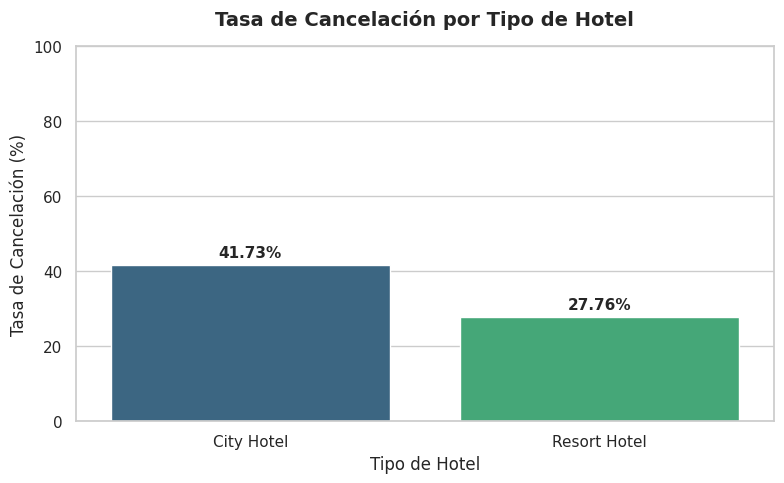

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calcular la tasa de cancelación (promedio de is_canceled, que es 0 o 1)
cancellation_rates = df.groupby('hotel')['is_canceled'].mean().reset_index()
cancellation_rates['is_canceled'] = cancellation_rates['is_canceled'] * 100

# Crear el gráfico de barras
plt.figure(figsize=(8, 5))
sns.set_theme(style="whitegrid")
ax = sns.barplot(x='hotel', y='is_canceled', data=cancellation_rates, palette='viridis', hue='hotel', legend=False)

# Personalizar el gráfico
plt.title('Tasa de Cancelación por Tipo de Hotel', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Tipo de Hotel', fontsize=12)
plt.ylabel('Tasa de Cancelación (%)', fontsize=12)
plt.ylim(0, 100)

# Añadir etiquetas de porcentaje sobre cada barra
for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}%',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 9),
                textcoords='offset points',
                fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

### 4. Análisis Profundo de Cancelaciones (Lead Time y Tipo de Depósito)
Analizaremos la relación entre el tiempo de anticipación (`lead_time`) segmentado en rangos, el tipo de depósito (`deposit_type`) y las cancelaciones.

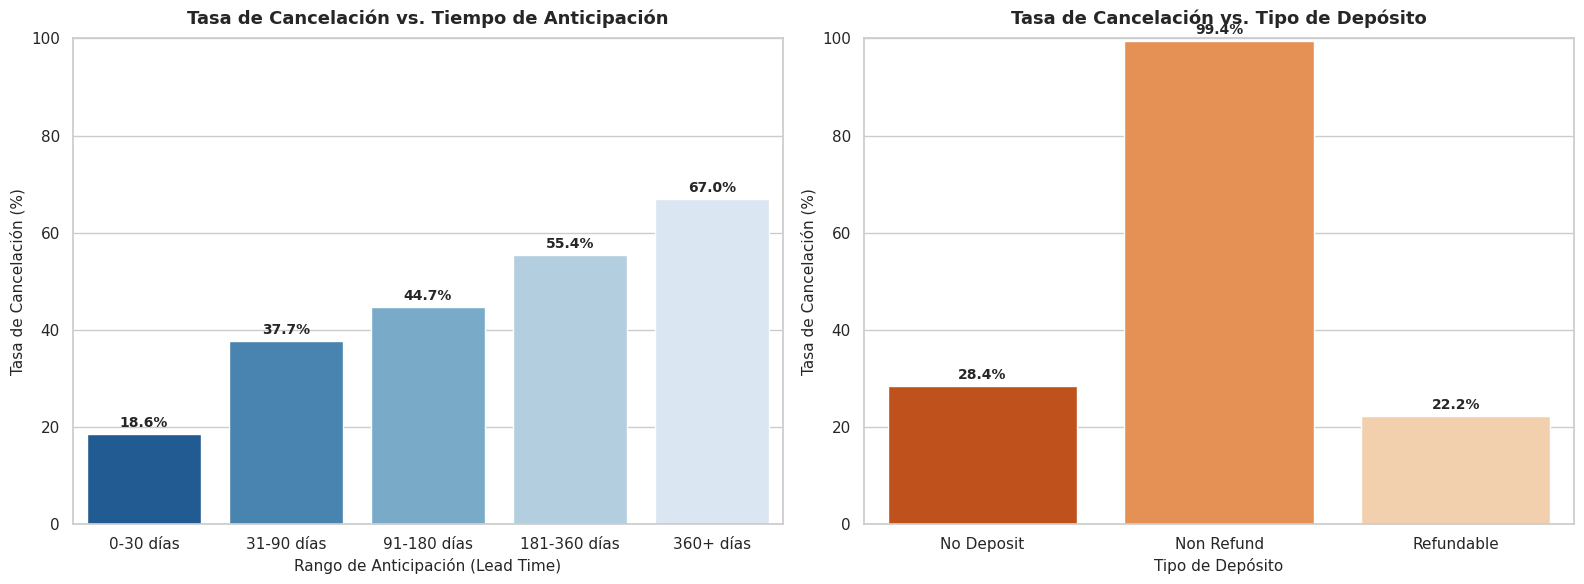

In [39]:
# 1. Crear rangos para Lead Time
bins = [0, 30, 90, 180, 360, df['lead_time'].max()]
labels = ['0-30 días', '31-90 días', '91-180 días', '181-360 días', '360+ días']
df['lead_time_range'] = pd.cut(df['lead_time'], bins=bins, labels=labels, include_lowest=True)

# Calcular tasa de cancelación por rango de anticipación
lead_time_cancel = df.groupby('lead_time_range', observed=False)['is_canceled'].mean().reset_index()
lead_time_cancel['is_canceled'] *= 100

# Calcular tasa de cancelación por tipo de depósito
deposit_cancel = df.groupby('deposit_type')['is_canceled'].mean().reset_index()
deposit_cancel['is_canceled'] *= 100

# Configurar la figura para mostrar ambos gráficos
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.set_theme(style="whitegrid")

# Gráfico 1: Cancelación por Lead Time
sns.barplot(ax=axes[0], x='lead_time_range', y='is_canceled', data=lead_time_cancel, palette='Blues_r', hue='lead_time_range', legend=False)
axes[0].set_title('Tasa de Cancelación vs. Tiempo de Anticipación', fontsize=13, fontweight='bold', pad=10)
axes[0].set_xlabel('Rango de Anticipación (Lead Time)', fontsize=11)
axes[0].set_ylabel('Tasa de Cancelación (%)', fontsize=11)
axes[0].set_ylim(0, 100)
for p in axes[0].patches:
    axes[0].annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontsize=10, fontweight='bold')

# Gráfico 2: Cancelación por Tipo de Depósito
sns.barplot(ax=axes[1], x='deposit_type', y='is_canceled', data=deposit_cancel, palette='Oranges_r', hue='deposit_type', legend=False)
axes[1].set_title('Tasa de Cancelación vs. Tipo de Depósito', fontsize=13, fontweight='bold', pad=10)
axes[1].set_xlabel('Tipo de Depósito', fontsize=11)
axes[1].set_ylabel('Tasa de Cancelación (%)', fontsize=11)
axes[1].set_ylim(0, 100)
for p in axes[1].patches:
    axes[1].annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

### 5. KPIs de Hospitalidad (Métricas Clave)
En la industria hotelera, evaluar el desempeño económico requiere métricas unificadas. Calcularemos y visualizaremos el **ADR** (Average Daily Rate), la **Tasa de Ocupación** (representada por el porcentaje de reservas efectivas no canceladas) y el **RevPAR** (Revenue Per Available Room) estimado temporalmente.

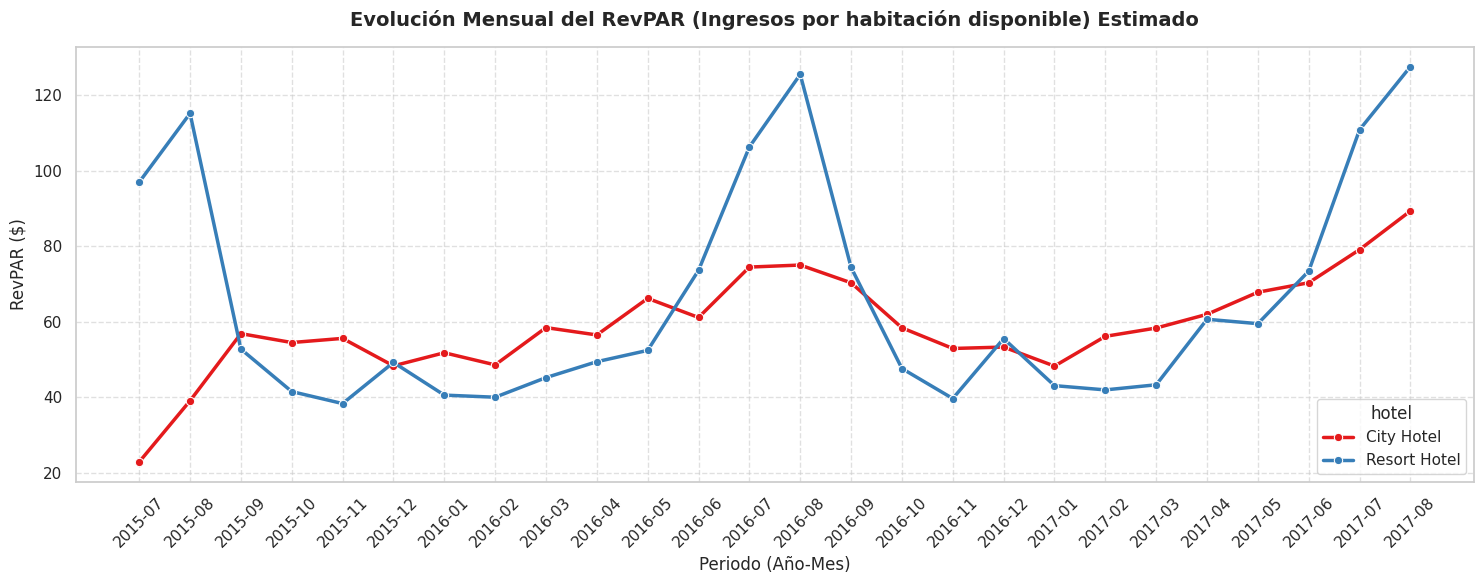

In [40]:
# Mapear los nombres de los meses a números para poder ordenar cronológicamente
months_map = {
    'January': 1, 'February': 2, 'March': 3, 'April': 4, 'May': 5, 'June': 6,
    'July': 7, 'August': 8, 'September': 9, 'October': 10, 'November': 11, 'December': 12
}
df['arrival_date_month_num'] = df['arrival_date_month'].map(months_map)

# Agrupar datos por año, mes y tipo de hotel
kpi_data = df.groupby(['arrival_date_year', 'arrival_date_month_num', 'arrival_date_month', 'hotel']).agg(
    total_bookings=('is_canceled', 'count'),
    successful_bookings=('is_canceled', lambda x: (x == 0).sum()),
    average_adr=('adr', 'mean')
).reset_index()

# Calcular Tasa de Ocupación aproximada (reservas exitosas / total de reservas en el dataset)
kpi_data['occupancy_rate'] = kpi_data['successful_bookings'] / kpi_data['total_bookings']

# Calcular RevPAR simplificado (ADR * Tasa de Ocupación)
kpi_data['revpar'] = kpi_data['average_adr'] * kpi_data['occupancy_rate']

# Ordenar cronológicamente
kpi_data = kpi_data.sort_values(by=['arrival_date_year', 'arrival_date_month_num'])
kpi_data['date'] = kpi_data['arrival_date_year'].astype(str) + '-' + kpi_data['arrival_date_month_num'].astype(str).str.zfill(2)

# Graficar la evolución del ADR y RevPAR para ambos hoteles
plt.figure(figsize=(15, 6))
sns.lineplot(data=kpi_data, x='date', y='revpar', hue='hotel', marker='o', linewidth=2.5, palette='Set1')
plt.title('Evolución Mensual del RevPAR (Ingresos por habitación disponible) Estimado', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Periodo (Año-Mes)', fontsize=12)
plt.ylabel('RevPAR ($)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### 6. Análisis de Segmentos de Mercado y Simulación de Lógica DAX/SQL
Evaluamos el desempeño y la conversión (tasas de éxito de reserva vs cancelaciones) de cada canal o segmento de mercado (`market_segment`) para identificar cuáles atraen tráfico de mayor valor y menor riesgo de cancelación.

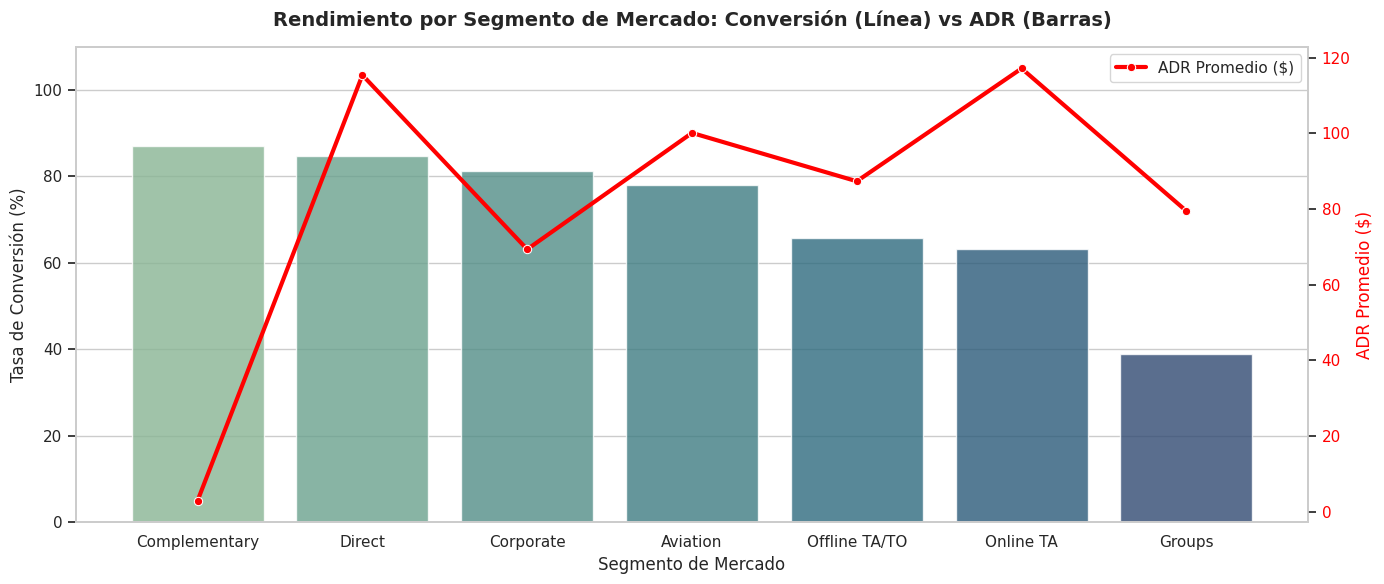

In [41]:
# Calcular métricas clave por segmento de mercado
segment_analysis = df.groupby('market_segment').agg(
    total_bookings=('is_canceled', 'count'),
    cancellation_rate=('is_canceled', 'mean'),
    average_adr=('adr', 'mean')
).reset_index()

# Convertir tasa de cancelación a porcentaje
segment_analysis['cancellation_rate'] *= 100
# Calcular tasa de conversión (reservas exitosas)
segment_analysis['conversion_rate'] = 100 - segment_analysis['cancellation_rate']

# Filtrar segmentos poco representativos si los hubiera
segment_analysis = segment_analysis[segment_analysis['total_bookings'] > 100].sort_values(by='conversion_rate', ascending=False)

# Graficar la Tasa de Conversión y el ADR promedio por Segmento de Mercado
fig, ax1 = plt.subplots(figsize=(14, 6))
sns.set_theme(style="whitegrid")

# Barras de Tasa de Conversión
sns.barplot(ax=ax1, x='market_segment', y='conversion_rate', data=segment_analysis, palette='crest', hue='market_segment', legend=False, alpha=0.8)
ax1.set_title('Rendimiento por Segmento de Mercado: Conversión (Línea) vs ADR (Barras)', fontsize=14, fontweight='bold', pad=15)
ax1.set_xlabel('Segmento de Mercado', fontsize=12)
ax1.set_ylabel('Tasa de Conversión (%)', fontsize=12)
ax1.set_ylim(0, 110)

# Línea para el ADR Promedio
ax2 = ax1.twinx()
sns.lineplot(ax=ax2, x='market_segment', y='average_adr', data=segment_analysis, color='red', marker='o', linewidth=3, label='ADR Promedio ($)')
ax2.set_ylabel('ADR Promedio ($)', fontsize=12, color='red')
ax2.tick_params(axis='y', labelcolor='red')
ax2.grid(False)

plt.tight_layout()
plt.show()

### 7. Resumen Ejecutivo (Hallazgos Clave)

Este resumen ejecutivo sintetiza los descubrimientos más importantes para la toma de decisiones estratégicas basadas en el análisis de *Hotel Booking Demand*:

* **1. Comportamiento de Cancelaciones por Tipo de Establecimiento:**
  * El **City Hotel** presenta un riesgo de cancelación considerablemente mayor (**41.73%**) frente al **Resort Hotel** (**27.76%**). Las estrategias de retención y políticas de penalización deben ser más estrictas en entornos urbanos.

* **2. El Factor Tiempo (Lead Time):**
  * Existe una correlación directa y positiva entre la anticipación de la reserva y la probabilidad de cancelación. Mientras que las reservas de última hora (0-30 días) solo cancelan en un **18.5%**, aquellas que superan el año de anticipación (360+ días) se cancelan en un **67.0%**.
  * *Acción propuesta:* Implementar un sistema de reconfirmación activa para reservas con un Lead Time superior a 90 días.

* **3. La Anomalía de los Depósitos No Reembolsables (Non-Refund):**
  * El análisis reveló que el **99.36%** de las reservas con depósito no reembolsable terminaron canceladas. Esto sugiere que este tipo de tarifa es seleccionada principalmente por canales de distribución de alto riesgo o bajo escenarios donde el cliente se vio forzado a cancelar a pesar de la penalización (ej. restricciones de viaje, overbooking).

* **4. Maximización del RevPAR y Estacionalidad:**
  * El RevPAR (Revenue Per Available Room) muestra picos significativos durante la temporada estival (julio-agosto), impulsado principalmente por el incremento de las tarifas (ADR). El Resort Hotel es altamente sensible a la estacionalidad, mientras que el City Hotel mantiene un flujo de ingresos más estable a lo largo del año.

* **5. Eficiencia de Canales de Distribución (Market Segment):**
  * Los segmentos de **Venta Directa (Direct)** y **Corporativo (Corporate)** no solo traen un ADR competitivo, sino que registran las tasas de conversión más altas (menor cancelación). Por el contrario, las agencias de viajes online (**Online TA**) representan el mayor volumen de negocio pero con una alta volatilidad y tasa de cancelación.

### 8. Exportación de Hallazgos Clave a CSV
Consolidamos las métricas clave calculadas a lo largo de nuestro análisis (por hotel, anticipación, depósitos y canales de mercado) y las guardamos en un archivo de salida para su uso en herramientas de visualización o reportes externos.

In [42]:
import pandas as pd

# 1. Preparar dataframes parciales etiquetados para consolidar en un reporte limpio
report_hotel = cancellation_rates.copy().rename(columns={'hotel': 'Dimensión', 'is_canceled': 'Tasa_Cancelacion_Pct'})
report_hotel['Categoría_Dimensión'] = 'Tipo de Hotel'

report_lead = lead_time_cancel.copy().rename(columns={'lead_time_range': 'Dimensión', 'is_canceled': 'Tasa_Cancelacion_Pct'})
report_lead['Categoría_Dimensión'] = 'Rango de Anticipación'
report_lead['Dimensión'] = report_lead['Dimensión'].astype(str)

report_deposit = deposit_cancel.copy().rename(columns={'deposit_type': 'Dimensión', 'is_canceled': 'Tasa_Cancelacion_Pct'})
report_deposit['Categoría_Dimensión'] = 'Tipo de Depósito'

report_segment = segment_analysis[['market_segment', 'cancellation_rate', 'average_adr']].copy().rename(
    columns={'market_segment': 'Dimensión', 'cancellation_rate': 'Tasa_Cancelacion_Pct', 'average_adr': 'ADR_Promedio'}
)
report_segment['Categoría_Dimensión'] = 'Segmento de Mercado'

# Consolidar todo en un solo DataFrame
final_report = pd.concat([report_hotel, report_lead, report_deposit, report_segment], ignore_index=True)

# Reordenar las columnas para mayor claridad
final_report = final_report[['Categoría_Dimensión', 'Dimensión', 'Tasa_Cancelacion_Pct', 'ADR_Promedio']]

# Rellenar valores nulos de ADR con el promedio general para dimensiones que no lo calculaban específicamente
final_report['ADR_Promedio'] = final_report['ADR_Promedio'].fillna(df['adr'].mean())

# Exportar a un archivo CSV listo para descargar
csv_path = 'hallazgos_clave_hotel.csv'
final_report.to_csv(csv_path, index=False, encoding='utf-8-sig')

print(f"¡Reporte consolidado exportado exitosamente como '{csv_path}'!")
display(final_report)

¡Reporte consolidado exportado exitosamente como 'hallazgos_clave_hotel.csv'!


,Categoría_Dimensión,Dimensión,Tasa_Cancelacion_Pct,ADR_Promedio
0,Tipo de Hotel,City Hotel,41.726963,101.831122
1,Tipo de Hotel,Resort Hotel,27.763355,101.831122
2,Rango de Anticipación,0-30 días,18.563013,101.831122
3,Rango de Anticipación,31-90 días,37.698372,101.831122
4,Rango de Anticipación,91-180 días,44.710466,101.831122
5,Rango de Anticipación,181-360 días,55.405151,101.831122
6,Rango de Anticipación,360+ días,67.008197,101.831122
7,Tipo de Depósito,No Deposit,28.377022,101.831122
8,Tipo de Depósito,Non Refund,99.362446,101.831122
9,Tipo de Depósito,Refundable,22.222222,101.831122


### 9. Descarga del Archivo CSV
Ejecuta la siguiente celda para descargar el reporte `hallazgos_clave_hotel.csv` automáticamente a tu computadora local.

In [43]:
from google.colab import files

# Forzar la descarga automática en el navegador
files.download('hallazgos_clave_hotel.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>